# Extra Credit: Hough Transform


### Programming Exercises

The main goal of this assignment is to investigate the Hough transform as discussed in Section 7.4.2 of [Szeliski](http://szeliski.org/Book "Computer Vision: Algorithms and Applications").


#### Preliminaries: Edge Detection

It is important that you trust your edge detection method before trying to implement the Hough Transform. It is recommended that you use the Canny Edge Detector in OpenCV, but you may use any method you prefer. Try out your code first on the <span style="color:orange;">2D_White_Box.png</span> image, then on the more complicated <span style="color:orange;">blocks.png</span> image.

Compute the gradient magnitude image for a grey image. Apply a suitable threshold to find edge points--play with the threshold to find the "best" solution. How well does this seem to work? Feel free to use any preprocessing you wish to prior to edge detection.

Note: Depending on your approach, you may end up with negative numbers or numbers larger than 255. Make sure you approprately scale the output images to display all of the information. Hint: try mapping negative values to [0,128) and positive values to (128,255].

2D_White_Box.png:
![alt 2D_White_Box.png](2D_White_Box.png)

blocks.png:
![alt blocks.png](blocks.png)


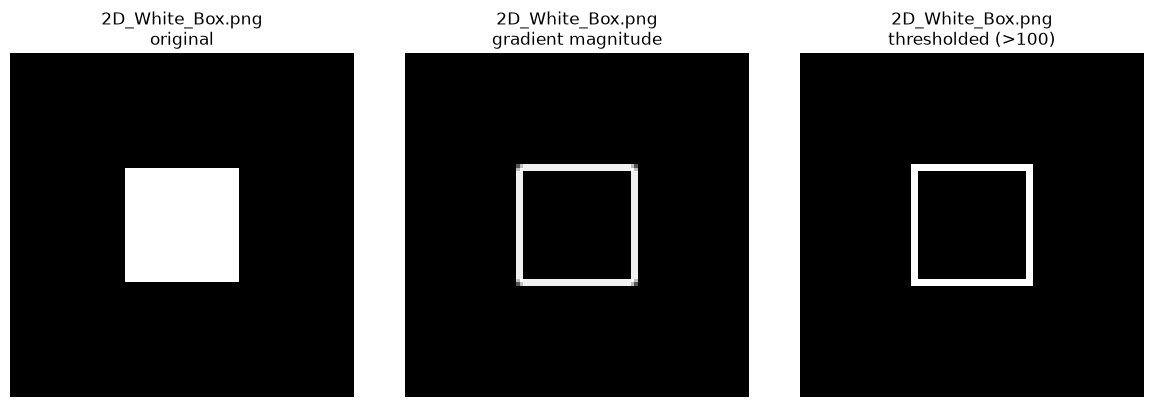

2D_White_Box.png: edge pixels = 256 (Canny: 124)


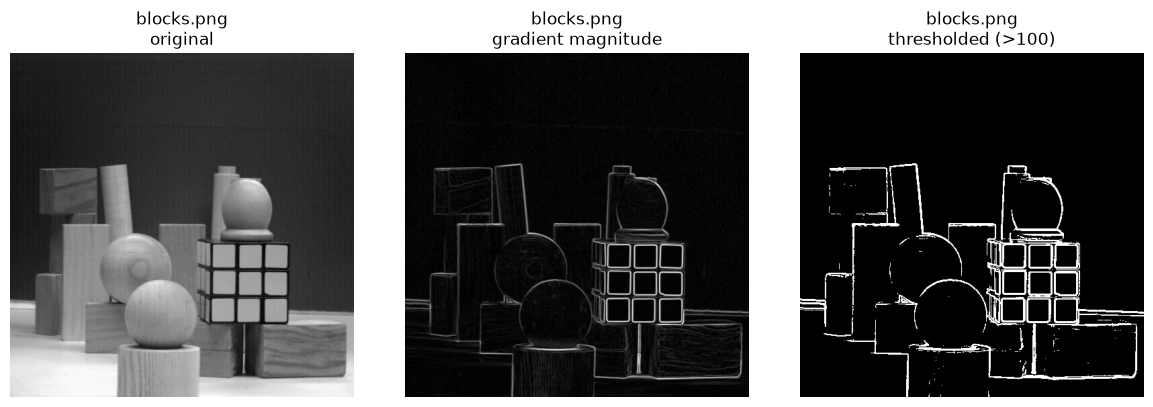

blocks.png: edge pixels = 14753 (Canny: 7712)


In [8]:
# Preliminaries: Compute the Gradient Magnitude
import cv2, os
import numpy as np
import matplotlib.pyplot as plt

def gradient_magnitude(gray):
    gx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
    return np.sqrt(gx**2 + gy**2)

for fname, thresh in [('2D_White_Box.png', 100), ('blocks.png', 100)]:
    gray = cv2.imread(fname, cv2.IMREAD_GRAYSCALE)
    mag = gradient_magnitude(gray)
    edges = (mag > thresh).astype(np.uint8) * 255   # binary edge map
    canny = cv2.Canny(gray, 50, 150)                # cleaner alternative

    plt.figure(figsize=(12, 4))
    for i, (img, t) in enumerate([(gray, 'original'),
                                  (mag / mag.max() * 255, 'gradient magnitude'),
                                  (edges, f'thresholded (>{thresh})')]):
        plt.subplot(1, 3, i + 1)
        plt.imshow(img, cmap='gray', vmin=0, vmax=255)
        plt.title(f"{fname}\n{t}"); plt.axis('off')
    plt.tight_layout(); plt.show()
    print(f"{fname}: edge pixels = {(edges > 0).sum()} (Canny: {(canny > 0).sum()})")



#### Programming Exercise: Hough Transform (up to 25 points)

Use the Hough transform to find all of the circular shapes in a color image. They occur in three (approximate) sizes: 32, 64, and 96 pixels in diameter. Try it out first on the simple <span style="color:orange;">simplecircle.png</span> image, then on the more complicated <span style="color:orange;">circles.png</span> image.

After finding maxima in the accumulator(s), write out a list of positions and sizes (small, medium, or large) for each circle.

Some of the cases are tricky--don't panic if you don't get them all, especially at first. For example, the image is quite noisy, some circles are occluded, and some circles even have centers outside the image, which can be difficult to find. Be sure to use preproccesing techniques (such as median filtering) to improve your chances.

Try to get as many as possible while generating as few possible false positives (erroneous identifications). Getting at least 10 of the circles is a reasonable goal. You will get 3 points for each correct identification and -2 point for each false positive.

To know what you should be shooting for, there are:

- 5 small circles (blue/cyan, light gray, purple clipped on the left, two eyes of the pumpkin).
- 12 medium circles (green one in the top left corner, orange/magenta/pink near top/left, yello, magenta, purple/cyan, medium grey in "target", med blue clipped on the left, red/white/blue on lower right).
- 3 Large circles (black in target, black/dark blue on right, and orange pumpkin).

You may implement the Hough Transform yourself or use OpenCV's HoughCircles function. If you use OpenCV's function, make sure you understand the function parameters.

For the <span style="color:orange;">circles.png</span> file, and each of the 3 diameters, show <span style="color:orange;">circles.png</span> with the detected circles outlined.

Again, you will get 3 points for each correct detection and -2 for each false positive. Even though it is possible you may detect more circles, the maximum possible extra credit for this assignment will be 25 points. 12 correct circles with 1 or 2 false positives is very respectable for an image this noisy. You may also complete this code in this notebook or in your own python file.

simplecircle.png:
![alt simplecircle.png](simplecircle.png)
circles.png:
![alt circles.png](circles.png)


simplecircle.png: [(124, 127, 32)]

Found 5 small, 6 medium, 2 large
  ( 17,  75) r=13  small
  ( 27, 151) r=17  small
  ( 53, 197) r=16  small
  ( 89, 115) r=15  small
  ( 90, 196) r=15  small
  ( 47,  33) r=30  medium
  ( 88, 114) r=32  medium
  (151,  33) r=32  medium
  (162,  71) r=27  medium
  (186, 207) r=32  medium
  (219,  34) r=31  medium
  ( 72, 198) r=48  large
  ( 89, 116) r=48  large


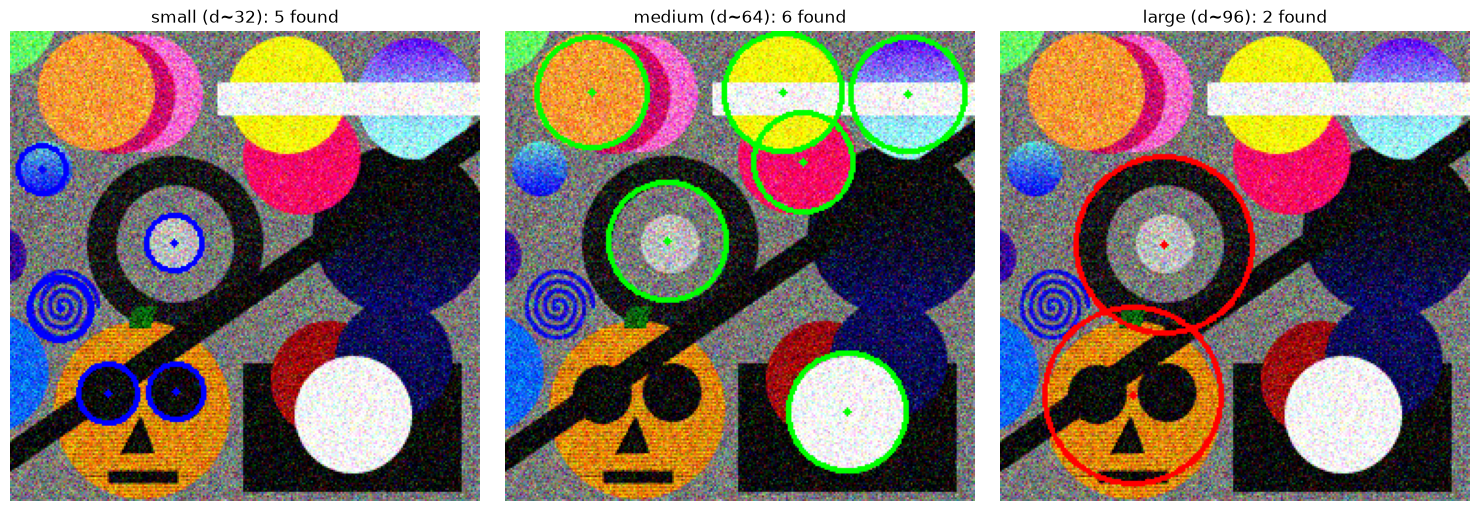

In [9]:
# Hough Transform
def find_circles(blurred, min_r, max_r, param2, min_dist=15):
    # param2 = votes needed to accept a circle (lower finds more, but more false alarms)
    c = cv2.HoughCircles(blurred, cv2.HOUGH_GRADIENT, dp=1, minDist=min_dist,
                         param1=100, param2=param2, minRadius=min_r, maxRadius=max_r)
    return [] if c is None else [(int(x), int(y), int(r)) for x, y, r in c[0]]

def draw(bgr, circles, color):
    out = bgr.copy()
    for x, y, r in circles:
        cv2.circle(out, (x, y), r, color, 2); cv2.circle(out, (x, y), 2, color, -1)
    return out

# Warm-up on the easy image
s = cv2.imread('simplecircle.png')
sg = cv2.medianBlur(cv2.cvtColor(s, cv2.COLOR_BGR2GRAY), 5)
print('simplecircle.png:', find_circles(sg, 20, 50, param2=20, min_dist=50))

# The hard, noisy image
img = cv2.imread('circles.png')
blur = cv2.medianBlur(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), 5)
small  = find_circles(blur, 12, 20, param2=16)   # d ~ 32
medium = find_circles(blur, 26, 38, param2=18)   # d ~ 64
large  = find_circles(blur, 42, 56, param2=16)   # d ~ 96

print(f"\nFound {len(small)} small, {len(medium)} medium, {len(large)} large")
for (x, y, r), s_ in zip(sorted(small) + sorted(medium) + sorted(large),
                          ['small']*len(small) + ['medium']*len(medium) + ['large']*len(large)):
    print(f"  ({x:3d}, {y:3d}) r={r:2d}  {s_}")

# Required views: one outlined image per diameter
plt.figure(figsize=(15, 5))
for i, (cs, col, name) in enumerate([(small, (255,0,0), 'small (d~32)'),
                                    (medium, (0,255,0), 'medium (d~64)'),
                                    (large, (0,0,255), 'large (d~96)')]):
    plt.subplot(1, 3, i + 1)
    plt.imshow(cv2.cvtColor(draw(img, cs, col), cv2.COLOR_BGR2RGB))
    plt.title(f"{name}: {len(cs)} found"); plt.axis('off')
plt.tight_layout(); plt.show()

